# Comprehensive Benchmark: Comparison of 6 Classification Models

In this lab, we benchmark all 6 classification algorithms trained on the **Iris dataset** under identical conditions:
1. **Logistic Regression**
2. **Support Vector Machine (SVM)**
3. **Decision Tree**
4. **Random Forest**
5. **Gaussian Naïve Bayes**
6. **Multi-Layer Perceptron (Neural Network)**

### 1. Importing modules and preparing dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### 2. Loading and Splitting Data

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame

X = df[iris.feature_names]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Train samples: 120, Test samples: 30


### 3. Training All 6 Models and Generating Predictions

In [3]:
# 1. Logistic Regression
lr = LogisticRegression(random_state=42).fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

# 2. SVM
svm = SVC(kernel="rbf", random_state=42).fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

# 3. Decision Tree
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# 4. Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 5. Naive Bayes
nb = GaussianNB().fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

# 6. Neural Network (MLP)
nn = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, random_state=42).fit(X_train_scaled, y_train)
y_pred_nn = nn.predict(X_test_scaled)

print("All 6 models trained and predictions generated!")

All 6 models trained and predictions generated!


### 4. Computing Metrics & Generating Comparison Table

In [4]:
models = {
    "Logistic Regression": y_pred_lr,
    "Support Vector Machine": y_pred_svm,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gaussian Naive Bayes": y_pred_nb,
    "Neural Network (MLP)": y_pred_nn
}

results = []
for model_name, y_pred in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test, y_pred, average="weighted")
    })

comparison_df = pd.DataFrame(results)

print("=" * 65)
print("FINAL MODEL BENCHMARK TABLE")
print("=" * 65)
print(comparison_df.round(4).to_string(index=False))

best_model = comparison_df.loc[comparison_df["Accuracy"].idxmax()]
print("\n" + "=" * 65)
print(f"Top Performer: {best_model['Model']} with {best_model['Accuracy']*100:.2f}% Accuracy")
print("=" * 65)

FINAL MODEL BENCHMARK TABLE
                 Model  Accuracy  Precision  Recall  F1-Score
   Logistic Regression    0.9333     0.9333  0.9333    0.9333
Support Vector Machine    0.9667     0.9697  0.9667    0.9666
         Decision Tree    0.9333     0.9333  0.9333    0.9333
         Random Forest    0.9000     0.9024  0.9000    0.8997
  Gaussian Naive Bayes    0.9667     0.9697  0.9667    0.9666
  Neural Network (MLP)    0.9667     0.9697  0.9667    0.9666

Top Performer: Support Vector Machine with 96.67% Accuracy


### 5. Visualizing Metric Comparisons (Bar Charts)

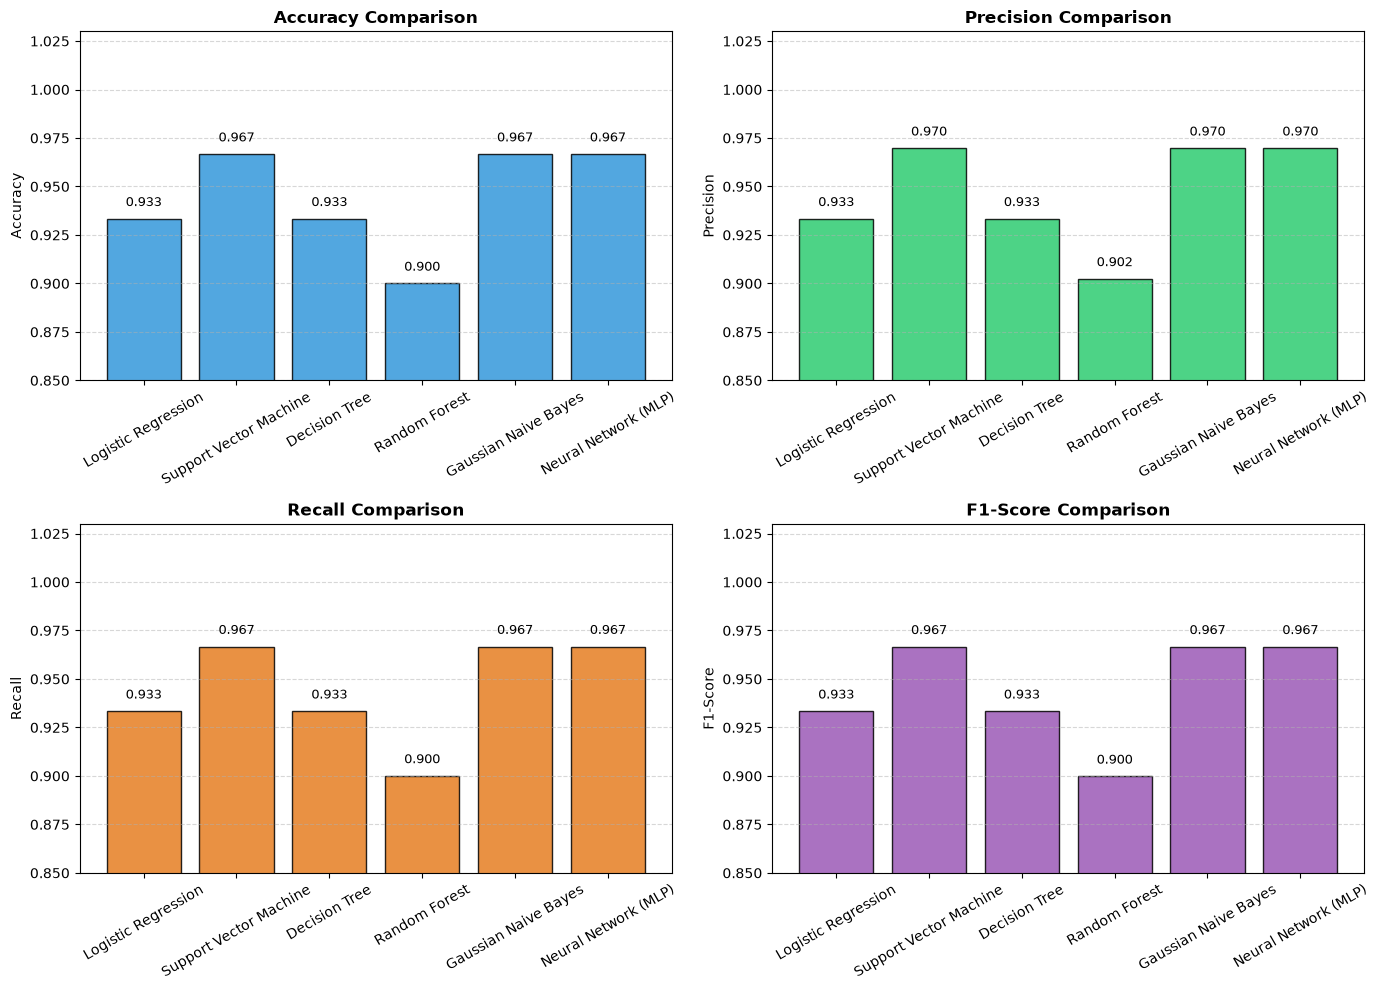

In [5]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
colors = ["#3498db", "#2ecc71", "#e67e22", "#9b59b6"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    bars = ax.bar(comparison_df["Model"], comparison_df[metric], color=colors[idx], alpha=0.85, edgecolor="black")
    ax.set_title(f"{metric} Comparison", fontsize=12, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_ylim(0.85, 1.03)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(True, linestyle="--", alpha=0.5, axis="y")
    
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 0.005, f"{h:.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()